# 04_train.ipynb
Copy từ 02 về nhưng giờ dùng dữ liệu đã engineer.

## 1. Import libraries và đọc dữ liệu
Đọc dữ liệu đã làm sạch.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle
import warnings
from sklearn.model_selection import train_test_split
from flaml import AutoML
import shap

warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
df = pd.read_csv("../data/processed/train_features.csv", keep_default_na=False)
df.head()

,MSSubClass,LotFrontage,LotArea,LotConfig,Neighborhood,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,...,SalePrice,TotalSF,TotalPorchSF,TotalBath,AreaPerRoom,HouseAge,RemodAge,HasEnclosedPorch,HasScreenPorch,HasWoodDeck
0,60,4.189655,9.042040,Inside,CollgCr,2Story,7,5,2003,2003,...,12.247699,7.850493,4.127134,3.5,5.369475,5,5,0,0,0
1,20,4.394449,9.169623,FR2,Veenker,1Story,6,8,1976,1976,...,12.109016,7.833996,0.000000,2.5,5.353437,31,31,0,0,1
2,60,4.234107,9.328212,Inside,CollgCr,2Story,7,5,2001,2002,...,12.317171,7.903596,3.761200,3.5,5.699328,7,6,0,0,0
3,70,4.110874,9.164401,Corner,Crawfor,2Story,7,5,1915,1970,...,11.849405,7.813592,5.730100,2.0,5.506492,91,36,1,0,0
4,60,4.442651,9.565284,FR2,NoRidge,2Story,8,5,2000,2000,...,12.429220,8.114923,4.442651,3.5,5.502165,8,8,0,0,1


## 2. Chia tập Train / Validation
Chia dữ liệu theo tỷ lệ 80% train / 20% validation với random_state=42 để cố định tập phân chia.

In [3]:
X = df.drop(columns=["SalePrice"])
y = df["SalePrice"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## 3. Huấn luyện mô hình bằng FLAML AutoML
Dùng automl để tìm mô hình và hyperparameter một cách tối giản.

In [4]:
automl = AutoML()

automl.fit(
    X_train=X_train,
    y_train=y_train,
    time_budget=120,
    metric="rmse",
    task="regression",
    seed=42,
    verbose=3
)

[flaml.automl.logger: 10-14 22:45:21] {2470} INFO - task = regression
[flaml.automl.logger: 10-14 22:45:21] {2481} INFO - Evaluation method: cv
[flaml.automl.logger: 10-14 22:45:21] {2584} INFO - Minimizing error metric: rmse
[flaml.automl.logger: 10-14 22:45:21] {2701} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd']
[flaml.automl.logger: 10-14 22:45:21] {3006} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 10-14 22:45:21] {3141} INFO - Estimated sufficient time budget=1042s. Estimated necessary time budget=7s.
[flaml.automl.logger: 10-14 22:45:21] {3192} INFO -  at 0.1s,	estimator lgbm's best error=3.0714e-01,	best estimator lgbm's best error=3.0714e-01
[flaml.automl.logger: 10-14 22:45:21] {3006} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 10-14 22:45:21] {3192} INFO -  at 0.2s,	estimator lgbm's best error=3.0714e-01,	best estimator lgbm's best error=3.0714e-01
[flaml.automl.logger: 10-14 22

## 4. Đánh giá độ chính xác
In tên thuật toán tốt nhất được lựa chọn và tính sai số RMSE trên tập validation.

In [5]:
print("Thuật toán tốt nhất:", automl.best_estimator)

val_pred = automl.predict(X_val)
val_rmse = np.sqrt(np.mean((y_val - val_pred) ** 2))
print(f"Validation RMSE: {val_rmse:.5f}")

Thuật toán tốt nhất: lgbm
Validation RMSE: 0.12482


## 5. Trực quan hóa bằng SHAP
Dùng thư viện SHAP để đánh giá độ quan trọng của từng cột.

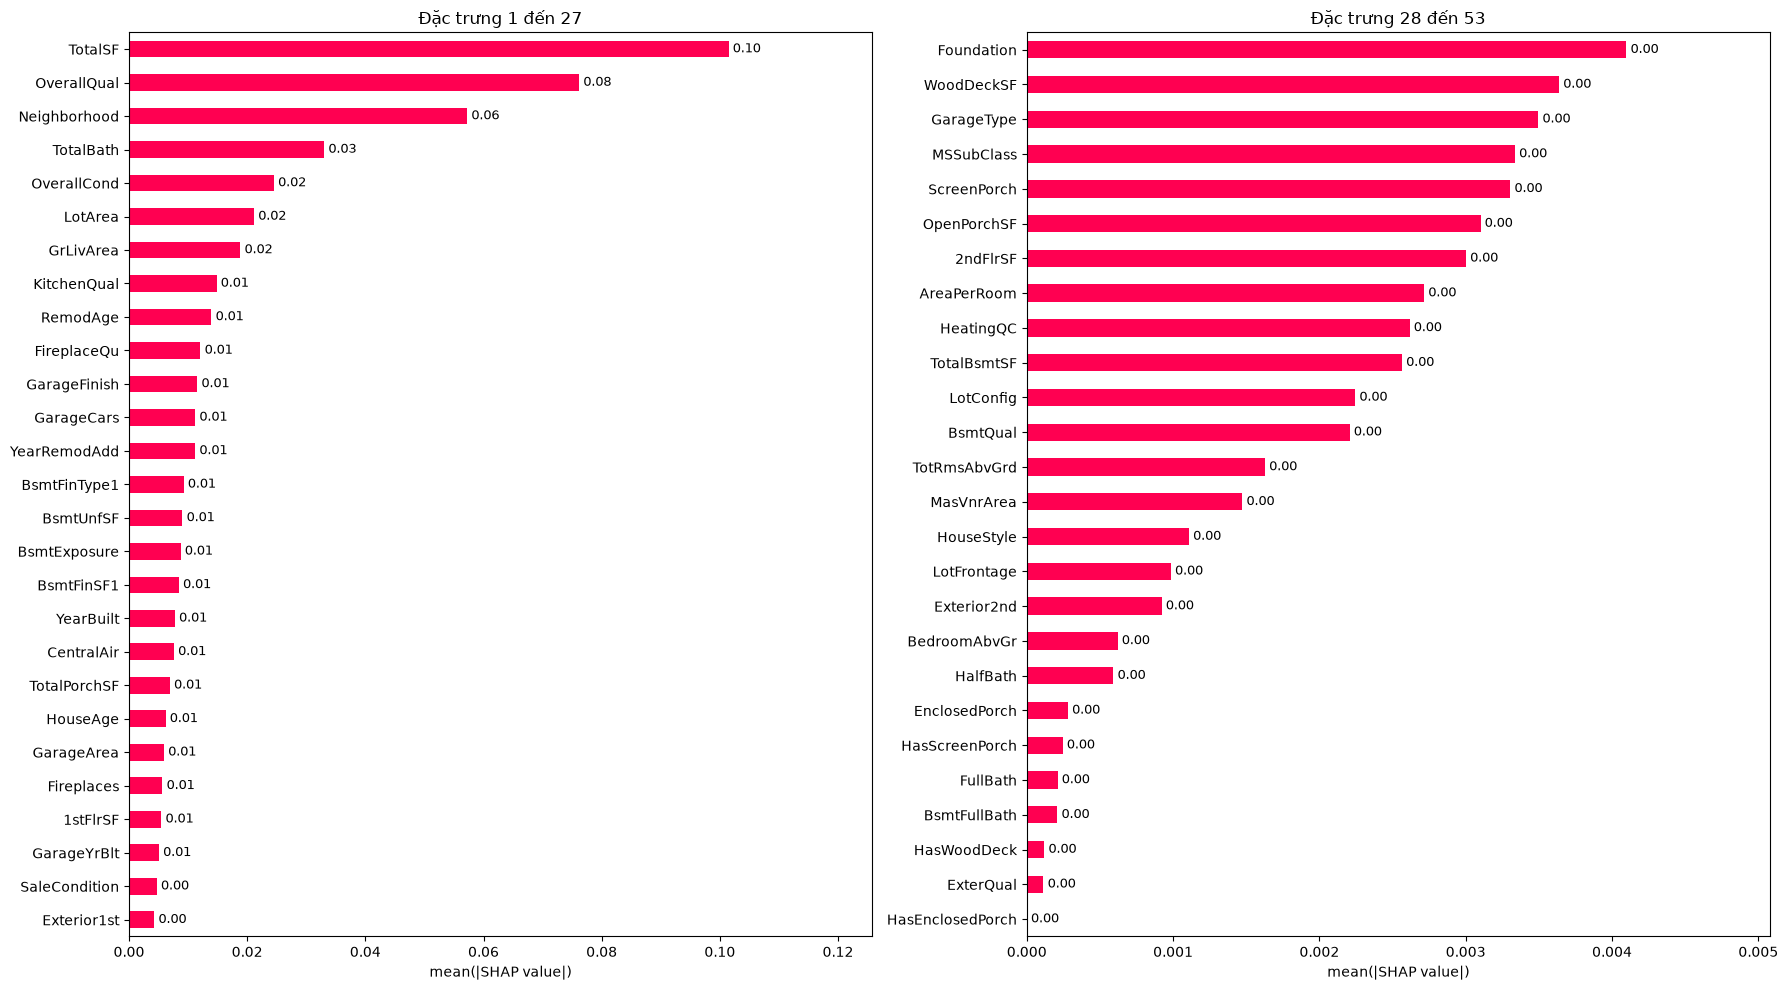

In [6]:
X_val_transformed = automl.model.preprocess(automl.preprocess(X_val))

explainer = shap.TreeExplainer(automl.model.estimator)
shap_values = explainer(X_val_transformed)

mean_shap = np.abs(shap_values.values).mean(axis=0)
feature_names = X_val_transformed.columns if hasattr(X_val_transformed, "columns") else shap_values.feature_names
shap_df = pd.Series(mean_shap, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))
chunk_size = int(np.ceil(len(shap_df) / 2))

for idx, ax in enumerate(axes):
    start = idx * chunk_size
    end = min(start + chunk_size, len(shap_df))
    chunk = shap_df.iloc[start:end].iloc[::-1]
    chunk.plot(kind="barh", ax=ax, color="#ff0051")
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize=9)
    ax.set_xlim(right=ax.get_xlim()[1] * 1.18)
    ax.set_title(f"Đặc trưng {start + 1} đến {end}")
    ax.set_xlabel("mean(|SHAP value|)")

plt.tight_layout()
plt.show()